# EDA na Prática

Nas aulas 9 e 10 vimos os quatro princípios da EDA (estrutural, distribucional, relacional e detecção de outliers/anomalias), como tratar dados ausentes e outliers, e como fazer análise descritiva, bivariada e multivariada. Hoje é a hora de **aplicarmos na prática**. Durante a primeira hora da aula, serão apresentadas as técnicas no dataset *Heart Disease* (UCI) e depois **cada aluno** irá aplicar as técnicas no dataset que foi escolhido semana passada.

*Relembrando*: a EDA não é uma linha reta

A EDA costuma ser apresentada como uma sequência de etapas (estrutura → tratamento → descrição → relação), mas na prática ela é **iterativa**: às vezes tratamos um outlier, olhamos a estatística descritiva de novo, e percebemos que precisa voltar atrás. Hoje vamos deixar isso explícito: olhamos a estatística descritiva **antes** de tratar dados ausentes/outliers (pra saber *como* tratar) e **depois** (pra confirmar o efeito do tratamento).

## Como funcionará a atividade

- **Duração:** ~1h40min
- **Formato:** individual
- **Passo 1:** acompanhem a demonstração no dataset Heart Disease.
- **Passo 2:** importem o dataset que vocês escolheram e enviaram anteriormente.
- **Passo 3:** repliquem o mesmo ciclo no dataset escolhido, respondendo às perguntas guiadas.
- **Uso de IA:** permitido, conforme o Plano de Ensino — documentem na seção final.

## Setup de Bibliotecas e Dados

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

## Carregando o Dataset

In [ ]:
import kagglehub
import pandas as pd
from pathlib import Path

# Baixa o dataset correto
pasta_dataset = Path(
    kagglehub.dataset_download(
        "emrey3lmaz/top-5-league-football-player-stats-2017-2025"
    )
)

# Caminho do CSV
arquivo_csv = (
    pasta_dataset /
    "Top5_League_Players_2017to2024_dataset.csv"
)

print("Arquivo utilizado:", arquivo_csv)

# Carrega os dados
df = pd.read_csv(
    arquivo_csv,
    sep=";",
    decimal=","
)

print("Linhas e colunas:", df.shape)
df.head()

Using Colab cache for faster access to the 'top-5-league-football-player-stats-2017-2025' dataset.
Arquivo utilizado: /kaggle/input/top-5-league-football-player-stats-2017-2025/Top5_League_Players_2017to2024_dataset.csv
Linhas e colunas: (22929, 178)


,league,season,team,player,nation_,pos_,age_,born_,Playing Time_MP,Playing Time_Starts,...,Performance_Crs,Performance_Fld,Performance_Fls,Performance_Int,Performance_OG,Performance_Off,Performance_PKcon,Performance_PKwon,Performance_Recov,Performance_TklW
0,ENG-Premier League,1718,Arsenal,Aaron Ramsey,WAL,MF,26.0,1990.0,24,21,...,17.0,33.0,28,24.0,0.0,0.0,0.0,2.0,128.0,27.0
1,ENG-Premier League,1718,Arsenal,Ainsley Maitland-Niles,ENG,"DF,MF",19.0,1997.0,15,8,...,20.0,5.0,10,12.0,0.0,0.0,1.0,0.0,73.0,17.0
2,ENG-Premier League,1718,Arsenal,Alex Iwobi,NGA,"MF,FW",21.0,1996.0,26,22,...,20.0,12.0,11,7.0,0.0,1.0,0.0,0.0,110.0,15.0
3,ENG-Premier League,1718,Arsenal,Alex Oxlade-Chamberlain,ENG,DF,23.0,1993.0,3,3,...,16.0,1.0,1,6.0,0.0,1.0,0.0,0.0,22.0,3.0
4,ENG-Premier League,1718,Arsenal,Alexandre Lacazette,FRA,FW,26.0,1991.0,32,26,...,16.0,28.0,28,7.0,0.0,23.0,0.0,1.0,53.0,17.0


## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.

**Antes de rodar:** o Heart Disease tem 13 variáveis preditoras (idade, sexo, tipo de dor no peito, pressão em repouso, colesterol, entre outras) mais o alvo (`num`, presença/grau de doença cardíaca). Quantas linhas vocês esperam que um dataset clínico como esse tenha — dezenas, centenas ou milhares de pacientes?

**Resposta:** Como a base reúne jogadores das cinco principais ligas europeias ao longo de várias temporadas, eu esperava milhares de registros. O resultado confirmou isso: são 22.929 linhas e 178 colunas.

### Dimensão e Tipos de Dados

In [ ]:
df.shape

(22929, 178)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22929 entries, 0 to 22928
Columns: 178 entries, league to Performance_TklW
dtypes: float64(151), int64(22), object(5)
memory usage: 31.1+ MB


In [ ]:
df.describe()

,season,age_,born_,Playing Time_MP,Playing Time_Starts,Playing Time_Min,Playing Time_90s,Performance_Gls,Performance_Ast,Performance_G+A,...,Performance_Crs,Performance_Fld,Performance_Fls,Performance_Int,Performance_OG,Performance_Off,Performance_PKcon,Performance_PKwon,Performance_Recov,Performance_TklW
count,22929.000000,22926.000000,22926.000000,22929.000000,22929.000000,22929.000000,22929.000000,22929.000000,22929.000000,22929.000000,...,22671.000000,22671.000000,22929.000000,22671.000000,22671.000000,22671.000000,22671.000000,22671.000000,22671.000000,22671.000000
mean,2069.550831,25.044142,1995.098753,18.519778,13.777225,1237.040298,13.745685,1.695800,1.184962,2.880762,...,22.780601,14.795510,15.417899,12.721715,0.053063,2.345860,0.204137,0.153985,64.747431,12.614353
std,233.633588,4.618257,5.102673,11.717082,11.446739,987.041131,10.966174,3.250874,1.971475,4.644488,...,38.564300,16.110032,14.796361,14.977373,0.240493,4.687467,0.500165,0.476044,60.225861,13.280123
min,1718.000000,14.000000,1977.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1819.000000,21.000000,1992.000000,7.000000,3.000000,291.000000,3.200000,0.000000,0.000000,0.000000,...,1.000000,2.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,13.000000,2.000000
50%,2122.000000,25.000000,1995.000000,19.000000,12.000000,1104.000000,12.300000,0.000000,0.000000,1.000000,...,6.000000,10.000000,12.000000,7.000000,0.000000,0.000000,0.000000,0.000000,49.000000,9.000000
75%,2223.000000,28.000000,1999.000000,29.000000,23.000000,2042.000000,22.700000,2.000000,2.000000,4.000000,...,28.000000,22.000000,24.000000,20.000000,0.000000,2.000000,0.000000,0.000000,102.000000,20.000000
max,2425.000000,42.000000,2009.000000,38.000000,38.000000,3420.000000,38.000000,41.000000,21.000000,49.000000,...,393.000000,167.000000,98.000000,112.000000,4.000000,57.000000,5.000000,6.000000,345.000000,98.000000


### Duplicadas

In [ ]:
df.duplicated().sum()

np.int64(0)

### Duplicadas pela chave do registro

Cada registro deveria representar um jogador em uma liga, temporada e clube. A chave usada foi **league + season + team + player**. A análise encontrou 512 linhas de Emanuele Torrasi com a mesma chave. As métricas principais eram iguais, mas algumas linhas tinham campos ausentes, indicando uma repetição criada na integração das tabelas. Por isso, foi mantido o registro mais completo e 511 linhas redundantes foram removidas. Depois do tratamento, não restaram chaves repetidas.

In [ ]:
chave = ["league", "season", "team", "player"]
duplicadas_logicas = df.duplicated(subset=chave, keep=False)

print("Linhas repetidas pela chave:", duplicadas_logicas.sum())
print("Linhas totalmente idênticas:", df.duplicated().sum())

grupos_repetidos = (
    df.loc[duplicadas_logicas, chave]
      .value_counts()
      .rename("quantidade")
      .reset_index()
)
display(grupos_repetidos.head())

# As 512 linhas pertencem ao mesmo jogador. As métricas principais são iguais,
# mas algumas versões têm campos ausentes. Mantemos o registro mais completo.
linhas_antes_duplicadas = len(df)
df["_n_ausentes_linha"] = df.isna().sum(axis=1)

criterios = ["_n_ausentes_linha"]
ordem = [True]
if "Subs_unSub" in df.columns:
    criterios.append("Subs_unSub")
    ordem.append(False)

df = (
    df.sort_values(criterios, ascending=ordem, kind="stable")
      .drop_duplicates(subset=chave, keep="first")
      .drop(columns="_n_ausentes_linha")
      .sort_index()
      .reset_index(drop=True)
)

print("Registros redundantes removidos:", linhas_antes_duplicadas - len(df))
print("Chaves repetidas após o tratamento:", df.duplicated(subset=chave).sum())
display(df.loc[df["player"].eq("Emanuele Torrasi"), chave + ["Playing Time_Min", "Performance_Gls", "Expected_xG"]])

Linhas repetidas pela chave: 512
Linhas totalmente idênticas: 0


,league,season,team,player,quantidade
0,ITA-Serie A,1718,Milan,Emanuele Torrasi,512


Registros redundantes removidos: 511
Chaves repetidas após o tratamento: 0


,league,season,team,player,Playing Time_Min,Performance_Gls,Expected_xG
17939,ITA-Serie A,1718,Milan,Emanuele Torrasi,6,0,0.0


## 2. Dados Faltantes

In [ ]:
df.isna().sum()

,0
league,0
season,0
team,0
player,0
nation_,10
...,...
Performance_Off,2
Performance_PKcon,2
Performance_PKwon,2
Performance_Recov,2


Antes de tratar os dados, é necessário verificar se as ausências são aleatórias ou se representam métricas que não se aplicam a alguns jogadores.

### Como interpretar o dataset

#### O que cada linha representa

Cada linha representa **a participação de um jogador em uma temporada e em um clube**. Por isso, o mesmo jogador pode aparecer várias vezes:

- uma vez em cada temporada;
- mais de uma vez na mesma temporada, caso tenha trocado de clube.

Portanto, a base **não representa apenas “um jogador por linha”**.

#### Padrão dos nomes das colunas

A maioria das colunas segue o padrão **Grupo_Métrica**:

- o termo antes do sublinhado indica a tabela de origem do FBref, como **Performance**, **Expected** ou **Tackles**;
- o termo depois do sublinhado indica a métrica.

Exemplo: **Performance_Gls** corresponde à coluna de gols (**Gls**) da tabela **Performance**.

---

#### Identificação: quem, onde e quando

- **league:** liga em que o jogador atuou, como ENG-Premier League.
- **season:** temporada em código. Exemplo: 1718 = 2017/18 e 2425 = 2024/25.
- **team:** clube.
- **player:** nome do jogador.
- **nation_:** nacionalidade em sigla de três letras, como ESP, FRA ou BRA.
- **pos_:** posição principal: GK (goleiro), DF (defensor), MF (meio-campo) e FW (atacante). Um jogador pode ter mais de uma posição, separada por vírgula, como DF,MF.
- **age_:** idade do jogador na temporada.
- **born_:** ano de nascimento.

#### Tempo de jogo

- **Playing Time_MP:** partidas jogadas.
- **Playing Time_Starts:** partidas em que começou como titular.
- **Playing Time_Min:** total de minutos em campo.
- **Playing Time_90s:** minutos convertidos em jogos completos de 90 minutos.

#### Desempenho em campo

- **Performance_Gls:** gols.
- **Performance_Ast:** assistências.
- **Performance_G+A:** gols + assistências.
- **Performance_G-PK:** gols sem contar pênaltis.
- **Performance_PK / PKatt:** pênaltis convertidos / cobrados.
- **Performance_CrdY / CrdR:** cartões amarelos / vermelhos.
- **Performance_Crs:** cruzamentos.
- **Performance_Fld / Fls:** faltas sofridas / cometidas.
- **Performance_Int:** interceptações.
- **Performance_OG:** gols contra.
- **Performance_Off:** impedimentos.
- **Performance_Recov:** bolas recuperadas.
- **Performance_TklW:** desarmes bem-sucedidos.

#### Métricas esperadas (xG)

Essas métricas medem a **qualidade das chances**, e não apenas o resultado. Um chute próximo ao gol possui xG maior que uma finalização de longa distância. A soma mostra quantos gols o jogador deveria marcar, aproximadamente, considerando as chances recebidas.

- **Expected_xG:** gols esperados.
- **Expected_npxG:** gols esperados sem pênaltis.
- **Expected_xAG / xA:** assistências esperadas.
- **Expected_G-xG:** gols marcados menos gols esperados. Valor positivo indica desempenho acima do esperado; valor negativo indica gols abaixo do esperado.

#### Métricas por 90 minutos

São as métricas ajustadas pelo tempo jogado. Elas permitem comparar, de forma mais justa, um titular com um reserva.

- **Per 90 Minutes_Gls / Ast / G+A / xG / xAG / npxG:** gols, assistências, participações em gols e métricas esperadas por 90 minutos.

#### Finalização

- **Standard_Sh:** total de finalizações.
- **Standard_SoT:** finalizações no gol.
- **Standard_SoT%:** percentual de finalizações no alvo.
- **Standard_Sh/90:** finalizações por 90 minutos.
- **Standard_G/Sh:** gols por finalização, indicando eficiência.
- **Standard_Dist:** distância média das finalizações.

#### Passes

- **Total_Att / Cmp / Cmp%:** passes tentados / certos / percentual de acerto.
- **Short_Cmp% / Medium_Cmp% / Long_Cmp%:** acerto em passes curtos / médios / longos.
- **KP_:** passes decisivos que geraram finalização.
- **1/3_:** passes para o último terço do campo.
- **PPA_ / CrsPA_:** passes / cruzamentos para dentro da área.

#### Criação de jogadas

- **SCA_SCA:** ações que levaram a uma finalização.
- **GCA_GCA:** ações que levaram a um gol.
- **SCA_SCA90 / GCA_GCA90:** as mesmas métricas por 90 minutos.

#### Defesa

- **Tackles_Tkl / TklW:** desarmes tentados / ganhos.
- **Int_:** interceptações.
- **Blocks_Blocks / Sh / Pass:** bloqueios totais / de chutes / de passes.
- **Clr_:** cortes para afastar a bola.
- **Err_:** erros que resultaram em finalização ou gol do adversário.

#### Condução e posse

- **Carries_Carries:** conduções de bola.
- **Carries_PrgC:** conduções progressivas que avançaram o time.
- **Carries_1/3 / CPA:** conduções até o último terço / até a área.
- **Touches_Touches:** total de toques na bola.
- **Touches_Att Pen:** toques na área adversária.

#### Dribles

- **Take-Ons_Att / Succ / Succ%:** dribles tentados / certos / percentual de sucesso.

#### Progressão

- **Progression_PrgC:** conduções progressivas.
- **Progression_PrgP:** passes progressivos.
- **Progression_PrgR:** recebimentos em posição avançada.

#### Impacto no time

- **Team Success_PPM:** pontos por partida do time com o jogador em campo.
- **Team Success_+/-:** saldo de gols com o jogador em campo.
- **Team Success_+/-90:** saldo de gols por 90 minutos.
- **Team Success_On-Off:** diferença de desempenho do time com e sem o jogador.

#### Duelos aéreos

- **Aerial Duels_Won / Lost / Won%:** duelos aéreos ganhos / perdidos / percentual de aproveitamento.

In [ ]:
faltantes = df.isna().sum()
resumo_faltantes = pd.DataFrame({
    "quantidade": faltantes,
    "percentual": (faltantes / len(df) * 100).round(2)
})
resumo_faltantes = resumo_faltantes.query("quantidade > 0").sort_values("percentual", ascending=False)

print("Colunas com ausentes:", len(resumo_faltantes))
resumo_faltantes.head(15)

Colunas com ausentes: 144


,quantidade,percentual
Standard_G/SoT,6893,30.75
Subs_Mn/Sub,4965,22.15
Starts_Mn/Start,4091,18.25
Standard_Dist,4089,18.24
Expected_npxG/Sh,4089,18.24
Standard_G/Sh,4087,18.23
Standard_SoT%,4087,18.23
Take-Ons_Succ%,3455,15.41
Take-Ons_Tkld%,3455,15.41
Challenges_Tkl%,2584,11.53


**Discussão:** alguma variável possui dados ausentes?

Sim, existem dados ausentes no dataset. Muitas ausências aparecem em métricas que não se aplicam a alguns jogadores, como porcentagens de acerto quando não houve nenhuma tentativa. Também existem poucos valores ausentes em informações como nacionalidade, idade e posição. Portanto, nem todos os dados faltantes significam erro de preenchimento.




In [ ]:
# Não é necessário código adicional nesta etapa.
# A presença e o significado dos dados ausentes foram analisados nas células acima.

**Etapa não executada:** não foi necessário um cálculo adicional, pois as quantidades e os percentuais de dados ausentes já foram apresentados e discutidos acima.

A próxima etapa investiga se os valores ausentes ocorrem juntos, o que ajuda a entender o mecanismo da ausência.

#### Identificando o mecanismo de dados ausentes

**Conhecimento de domínio**

Neste dataset, as ausências têm causas diferentes:

- `nation_`, `pos_`, `age_` e `born_` têm poucas ausências e provavelmente não foram informadas na fonte.
- Algumas porcentagens ficam ausentes quando não houve nenhuma tentativa. Por exemplo, `Standard_G/SoT` não pode ser calculada quando o jogador teve zero chutes no gol.
- Um conjunto de métricas avançadas tem 258 ausências nas mesmas linhas, indicando uma falha sistemática de coleta ou integração da fonte, e não ausências ao acaso.

### As ausências ocorrem juntas?

Contar os ausentes por coluna não mostra a história toda. Se duas colunas ficam ausentes nas mesmas linhas, isso indica um possível padrão sistemático, como uma métrica que não foi registrada e afeta várias medidas ao mesmo tempo.

In [ ]:
coluna_1 = "Expected_xG"
coluna_2 = "Expected_xAG"

tabela_contingencia = pd.crosstab(
    df[coluna_1].isna(),
    df[coluna_2].isna(),
    rownames=[f"{coluna_1} ausente"],
    colnames=[f"{coluna_2} ausente"]
)

ambas_ausentes = (df[coluna_1].isna() & df[coluna_2].isna()).sum()
print("Linhas com as duas features ausentes:", ambas_ausentes)
tabela_contingencia

Linhas com as duas features ausentes: 2


Expected_xAG ausente,False,True
Expected_xG ausente,,
False,22416,0
True,0,2


Como várias métricas avançadas têm ausências, analisamos `Expected_xG` e `Expected_xAG`. As duas estão ausentes nas mesmas 258 linhas, o que indica um padrão sistemático.

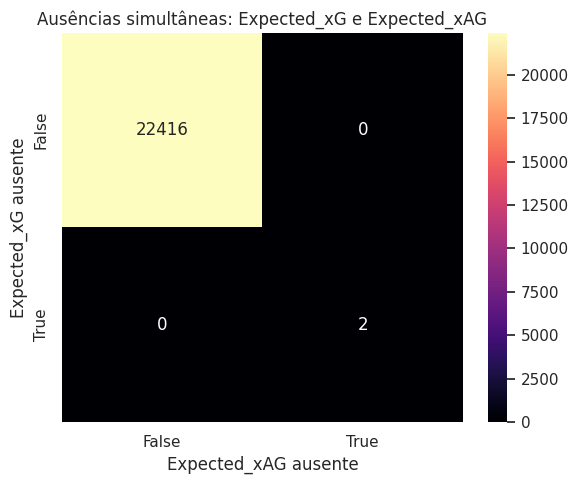

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title("Ausências simultâneas: Expected_xG e Expected_xAG")
plt.tight_layout()
plt.show()

**Pra discutir:** quantas linhas têm as duas colunas ausentes ao mesmo tempo? Isso muda a hipótese sobre o mecanismo de ausência (MCAR/MAR/MNAR), ou parecem eventos independentes?

*Relembrando:*
- MCAR: Mecanismo Aleatório e sem viés
- MAR: Mecanismo Randômico e com viés possível de corrigir
- MNAR: Mecanismo Não Randômico relacionada a própria feature

**Resposta:** Existem 258 linhas em que `Expected_xG` e `Expected_xAG` estão ausentes ao mesmo tempo. Portanto, as ausências não parecem independentes. A hipótese mais provável é MAR, pois o padrão parece estar ligado à coleta ou à fonte dos dados, e não ao próprio valor de xG. Já algumas porcentagens ausentes representam casos em que não houve tentativa e a métrica não pôde ser calculada.

**Nota para quando vocês replicarem no dataset de vocês:** se o dataset escolhido tiver *muitas* colunas com *muitos* ausentes, aí sim uma correlação (ou um heatmap) entre os indicadores de ausência passa a fazer sentido. O problema neste caso foi o volume pequeno, não a técnica em si.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção. Por exemplo, se uma variável for muito assimétrica, faz mais sentido imputar com a mediana do que com a média.

In [ ]:
COL_POS = "pos_" if "pos_" in df.columns else "pos"
COL_IDADE = "age_" if "age_" in df.columns else "age"

# Classe de comparação (equivalente ao "doenca_cardiaca" do exemplo):
# atacantes x demais posições, a partir da posição principal do jogador.
df["pos_principal"] = df[COL_POS].str.split(",").str[0]
df["perfil"] = np.where(df["pos_principal"] == "FW", "Atacante", "Demais")

VARS_QUANT = [COL_IDADE, "Playing Time_Min", "Performance_Gls", "Expected_xG", "Total_Cmp%"]
VARS_QUALI = ["league", "season", "pos_principal", "perfil"]

print("Colunas não encontradas:", [c for c in VARS_QUANT if c not in df.columns])
print(df["perfil"].value_counts())

### Tabela descritiva, com assimetria e curtose

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

Colunas não encontradas: []
perfil
Demais      16842
Atacante     5576
Name: count, dtype: int64


,mean,median,std,min,max,skewness,kurtosis
age_,25.20,25.00,4.55,14.00,42.00,0.29,-0.44
Playing Time_Min,1265.10,1139.00,980.37,1.00,3420.00,0.37,-1.07
Performance_Gls,1.73,0.00,3.28,0.00,41.00,3.58,18.34
Expected_xG,1.77,0.70,2.95,0.00,33.20,3.41,16.17
Total_Cmp%,76.24,77.40,11.28,0.00,100.00,-1.47,6.94


**Resposta:** as duas métricas ofensivas são as assimétricas: `Performance_Gls` (skewness 3,62 e kurtosis 18,73) e `Expected_xG` (3,42 e 16,33). A maior parte dos jogadores termina a temporada com pouquíssimos gols — a mediana de gols é 0 — e um grupo pequeno de artilheiros puxa a cauda direita até 41 gols. `Total_Cmp%` é assimétrica à esquerda (-1,35) e com cauda pesada (6,44), porque quase todo profissional acerta uma fração alta dos passes e só os casos raros de aproveitamento baixíssimo ficam na ponta esquerda. Já a idade (0,29 e -0,48) e `Playing Time_Min` (0,39 e -1,06) são praticamente simétricas e mais achatadas que a normal.

Isso é coerente com o domínio: gol é evento raro, passe certo é rotina, idade de atleta profissional se concentra entre uns 20 e 33 anos e os minutos se espalham de forma quase uniforme entre reservas e titulares. Consequência prática pra Seção 4: nas variáveis muito assimétricas a mediana representa melhor o jogador típico do que a média, e qualquer imputação deveria usar a mediana — ou zero, quando a ausência for estrutural.

### Distribuições de dados

Onde fizer sentido, comparamos "Demais posições" (rosa) vs. "Atacante" (roxo). Vamos utilizar esta convenção de cor que vamos manter até a análise bivariada.

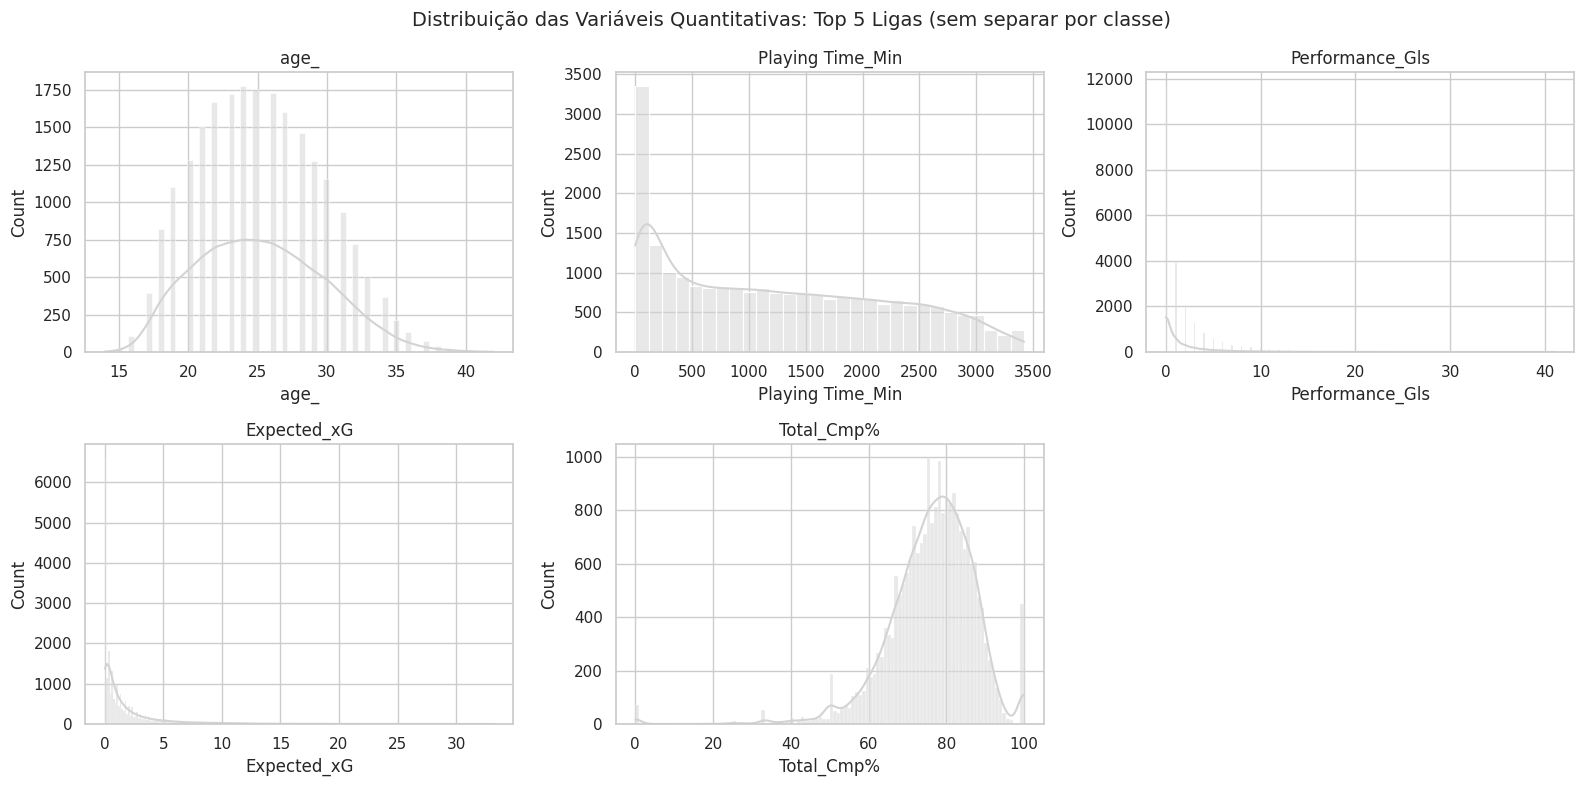

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle("Distribuição das Variáveis Quantitativas: Top 5 Ligas (sem separar por classe)", fontsize=14)
plt.tight_layout()
plt.show()

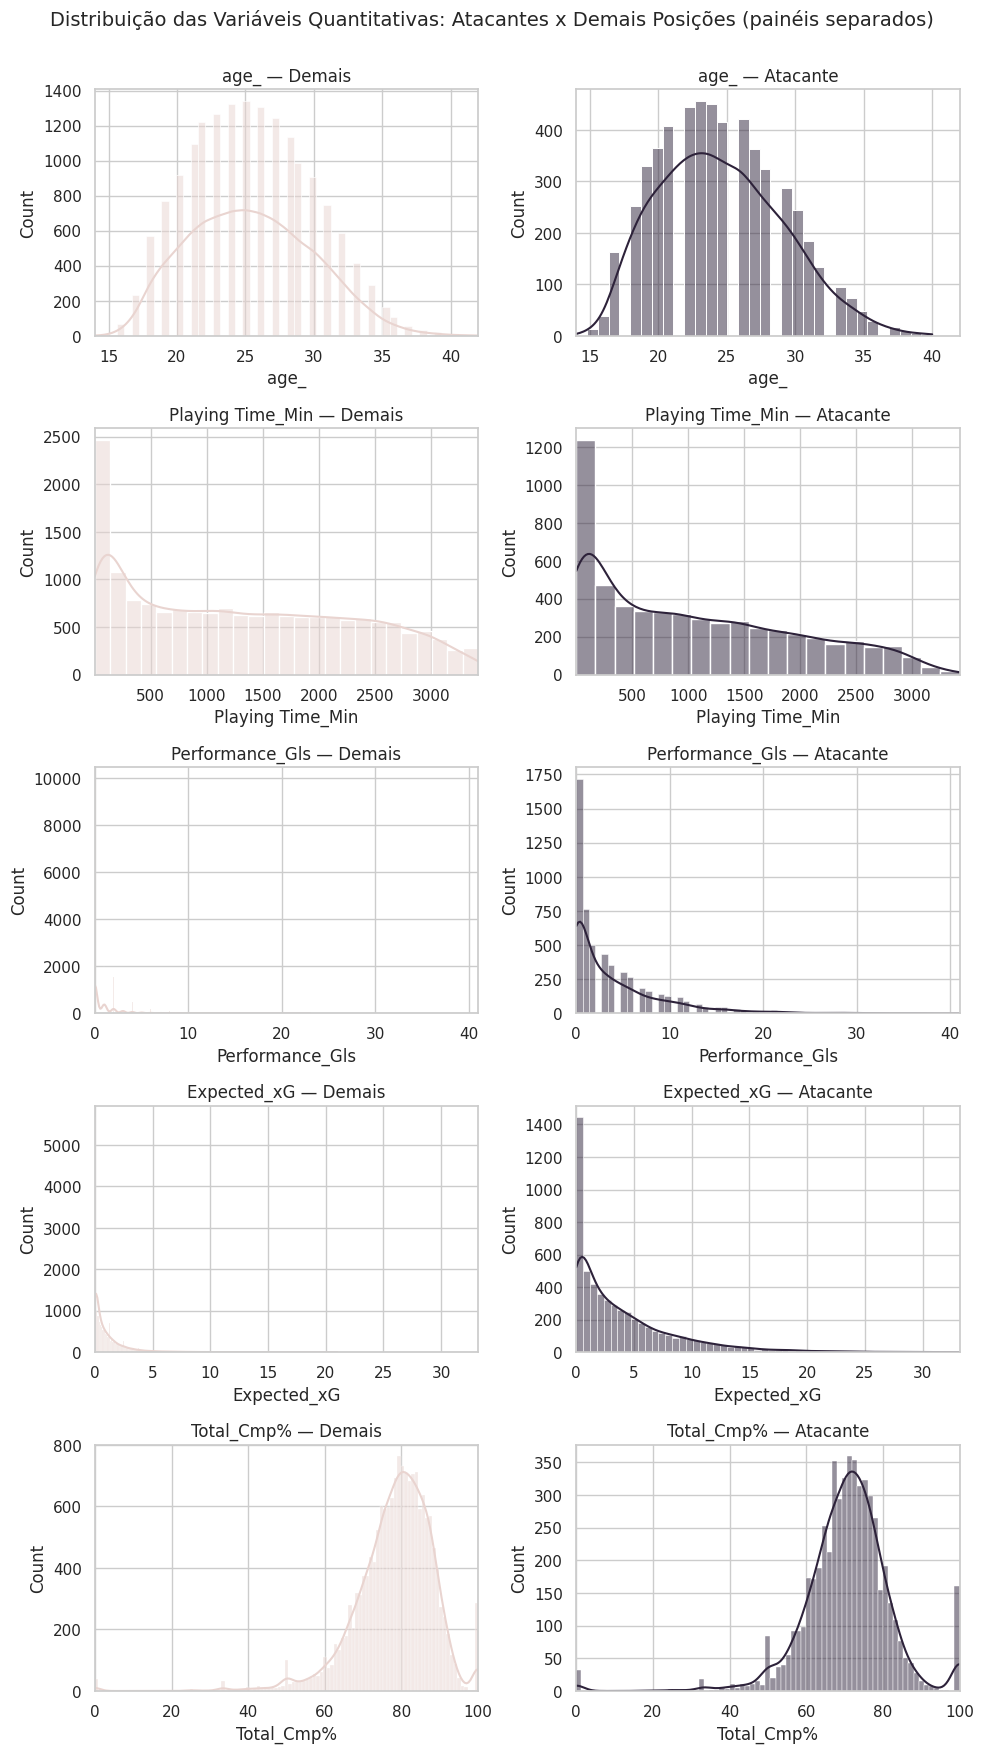

In [ ]:
fig, axes = plt.subplots(len(VARS_QUANT), 2, figsize=(10, 3.5 * len(VARS_QUANT)))

for i, col in enumerate(VARS_QUANT):
    lim = (df[col].min(), df[col].max())
    for j, (classe, cor) in enumerate([("Demais", COR_CONTEXTO), ("Atacante", COR_DESTAQUE)]):
        subset = df[df["perfil"] == classe]
        sns.histplot(data=subset, x=col, kde=True, color=cor, ax=axes[i, j])
        axes[i, j].set_xlim(lim)
        axes[i, j].set_title(f"{col} — {classe}")

fig.suptitle("Distribuição das Variáveis Quantitativas: Atacantes x Demais Posições (painéis separados)", fontsize=14, y=1.001)
plt.tight_layout()
plt.show()

**Para discutir:** agora que as classes estão em painéis separados (mesma escala de eixo X em cada linha), fica mais fácil ver: alguma variável parece ter formato bem diferente entre "Demais" e "Atacante"?

**Resposta:** Sim. `Performance_Gls` e `Expected_xG` mudam de formato: no grupo "Demais" a massa fica quase toda concentrada em zero, enquanto nos atacantes a distribuição se espalha bem mais à direita. Já `Playing Time_Min` e a idade têm formato parecido nos dois grupos. Ou seja, o que separa um atacante dos demais jogadores é a produção ofensiva, não o tempo em campo nem a idade.

#### Testes de Aderência

*Será que o número de gols na temporada segue uma distribuição normal?*

O Shapiro-Wilk é o teste de aderência mais usado pra normalidade, junto com o QQ-Plot como visualização de apoio. Vamos testar com `Performance_Gls`. Como a base tem ~23 mil linhas e o Shapiro-Wilk perde precisão acima de ~5.000 observações, rodamos o teste em uma amostra aleatória de 5.000 jogadores-temporada.

Shapiro-Wilk — Performance_Gls (amostra de 5.000): estatística=0.6006, p-valor=2.299e-75
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


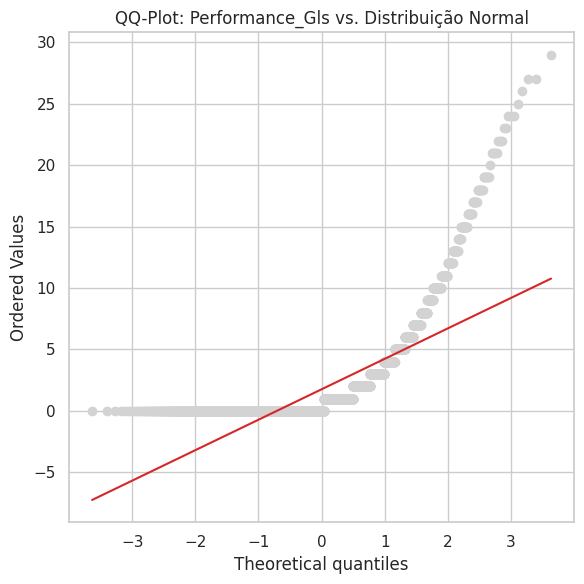

In [ ]:
VAR_FOCO = "Performance_Gls"

amostra = df[VAR_FOCO].dropna().sample(5000, random_state=42)

stat_sw, p_valor_sw = stats.shapiro(amostra)
print(f"Shapiro-Wilk — {VAR_FOCO} (amostra de 5.000): estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")

"""### QQ-Plot — gols na temporada"""

fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(amostra, dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title(f"QQ-Plot: {VAR_FOCO} vs. Distribuição Normal")
plt.tight_layout()
plt.show()

**Como interpretar:** se os pontos cinza acompanhassem de perto a reta vermelha, a distribuição seria aproximadamente normal. O afastamento nas extremidades indica assimetria ou caudas diferentes da normal, o que concorda com o teste de Shapiro-Wilk.

Foi utilizada uma amostra de **5.000 observações**. Como amostras grandes tornam o teste mais sensível, a decisão não foi baseada apenas no p-valor: também foram observadas a assimetria e a forma do QQ-Plot. As três evidências apontam contra a normalidade.

Quando o teste rejeita H0, com p < 0,05, a conclusão correta é: **há evidência estatística de que a variável não segue distribuição normal**.

In [ ]:
resultados_shapiro = []
for col in VARS_QUANT:
    serie = df[col].dropna()
    amostra_col = serie.sample(5000, random_state=42) if len(serie) > 5000 else serie
    stat, p = stats.shapiro(amostra_col)
    resultados_shapiro.append({"variavel": col, "estatistica": round(stat, 4),
                                "p_valor": round(p, 6), "rejeita_normalidade": p < 0.05})

pd.DataFrame(resultados_shapiro).set_index("variavel")

,estatistica,p_valor,rejeita_normalidade
variavel,,,
age_,0.9830,0.0,True
Playing Time_Min,0.9330,0.0,True
Performance_Gls,0.6006,0.0,True
Expected_xG,0.6288,0.0,True
Total_Cmp%,0.9313,0.0,True


**Resposta:** nenhuma das cinco variáveis passa no teste. O Shapiro-Wilk rejeita H0 em todas (p < 0,05), e a estatística mostra a diferença de grau: `Performance_Gls` (W = 0,58) e `Expected_xG` (W = 0,62) estão muito longe da normal, enquanto a idade (W = 0,98) é a que mais se aproxima — mas ainda assim rejeita. O QQ-Plot de `Performance_Gls` confirma: os pontos se afastam muito da reta e formam degraus, formato típico de variável de contagem com excesso de zeros.

Duas ressalvas de interpretação, seguindo a nota da aula:

1. **Tamanho da amostra:** com quase 23 mil linhas o teste fica sensível demais e rejeitaria até desvios triviais. Por isso rodamos em uma amostra aleatória de 5.000 observações — e mesmo assim o resultado se mantém, então não é artefato do tamanho da base.
2. **Como afirmar o resultado:** como o teste rejeitou H0, a frase correta é "temos evidência estatística contra a normalidade" (conclusão forte), e não "não podemos garantir normalidade". Ela é reforçada por três evidências que concordam: skewness alto, QQ-Plot afastado da reta e o próprio Shapiro-Wilk.

Na prática, isso desaconselha técnicas que exijam normalidade nessas variáveis; testes não paramétricos (ou uma transformação, como a do fim da Seção 4) são o caminho mais seguro.

**ECDF — outra forma de ver a distribuição**

Diferente do histograma, a ECDF não depende de escolher o número de bins: para cada valor no eixo X, a curva mostra a proporção acumulada de observações menores ou iguais àquele valor. É especialmente útil pra comparar duas distribuições lado a lado — onde as curvas se distanciam mais é onde a diferença entre os grupos é mais perceptível.

Vamos ilustrar com uma única variável (`Expected_xG`, gols esperados), comparando atacantes e demais posições.

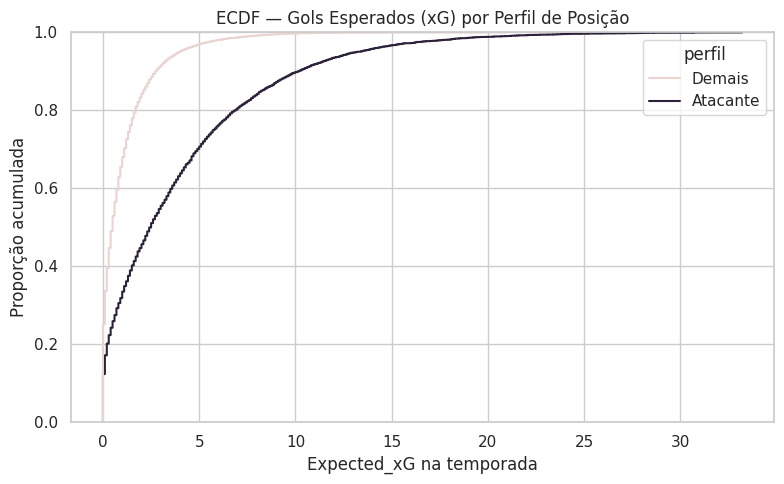

In [ ]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=df, x="Expected_xG", hue="perfil",
             palette={"Demais": COR_CONTEXTO, "Atacante": COR_DESTAQUE})
plt.title("ECDF — Gols Esperados (xG) por Perfil de Posição")
plt.xlabel("Expected_xG na temporada")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

### Métricas de Tendência Central

Nesta etapa, comparamos média e mediana para entender o centro da distribuição.

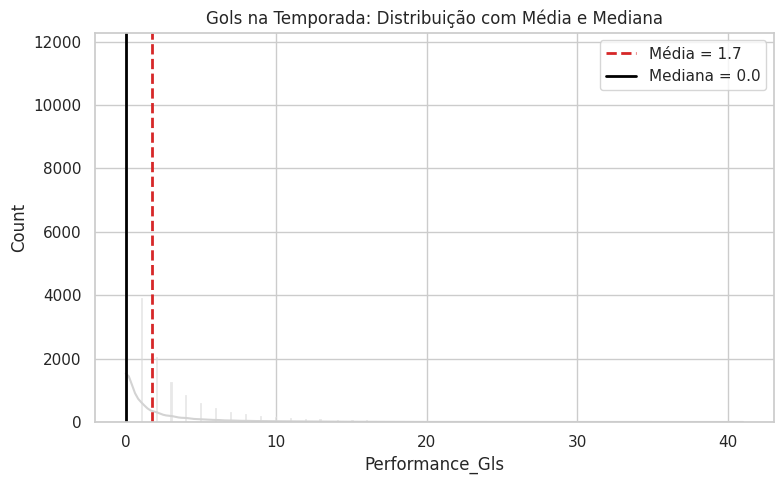

In [ ]:
media_gols = df["Performance_Gls"].mean()
mediana_gols = df["Performance_Gls"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Performance_Gls", kde=True, color=COR_NEUTRA)
plt.axvline(media_gols, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_gols:.1f}")
plt.axvline(mediana_gols, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_gols:.1f}")
plt.title("Gols na Temporada: Distribuição com Média e Mediana")
plt.legend()
plt.tight_layout()
plt.show()

### Dispersão

,var,std,IQR
age_,20.66,4.55,6.0
Playing Time_Min,961125.77,980.37,1721.0
Performance_Gls,10.74,3.28,2.0
Expected_xG,8.68,2.95,2.0
Total_Cmp%,127.17,11.28,13.1


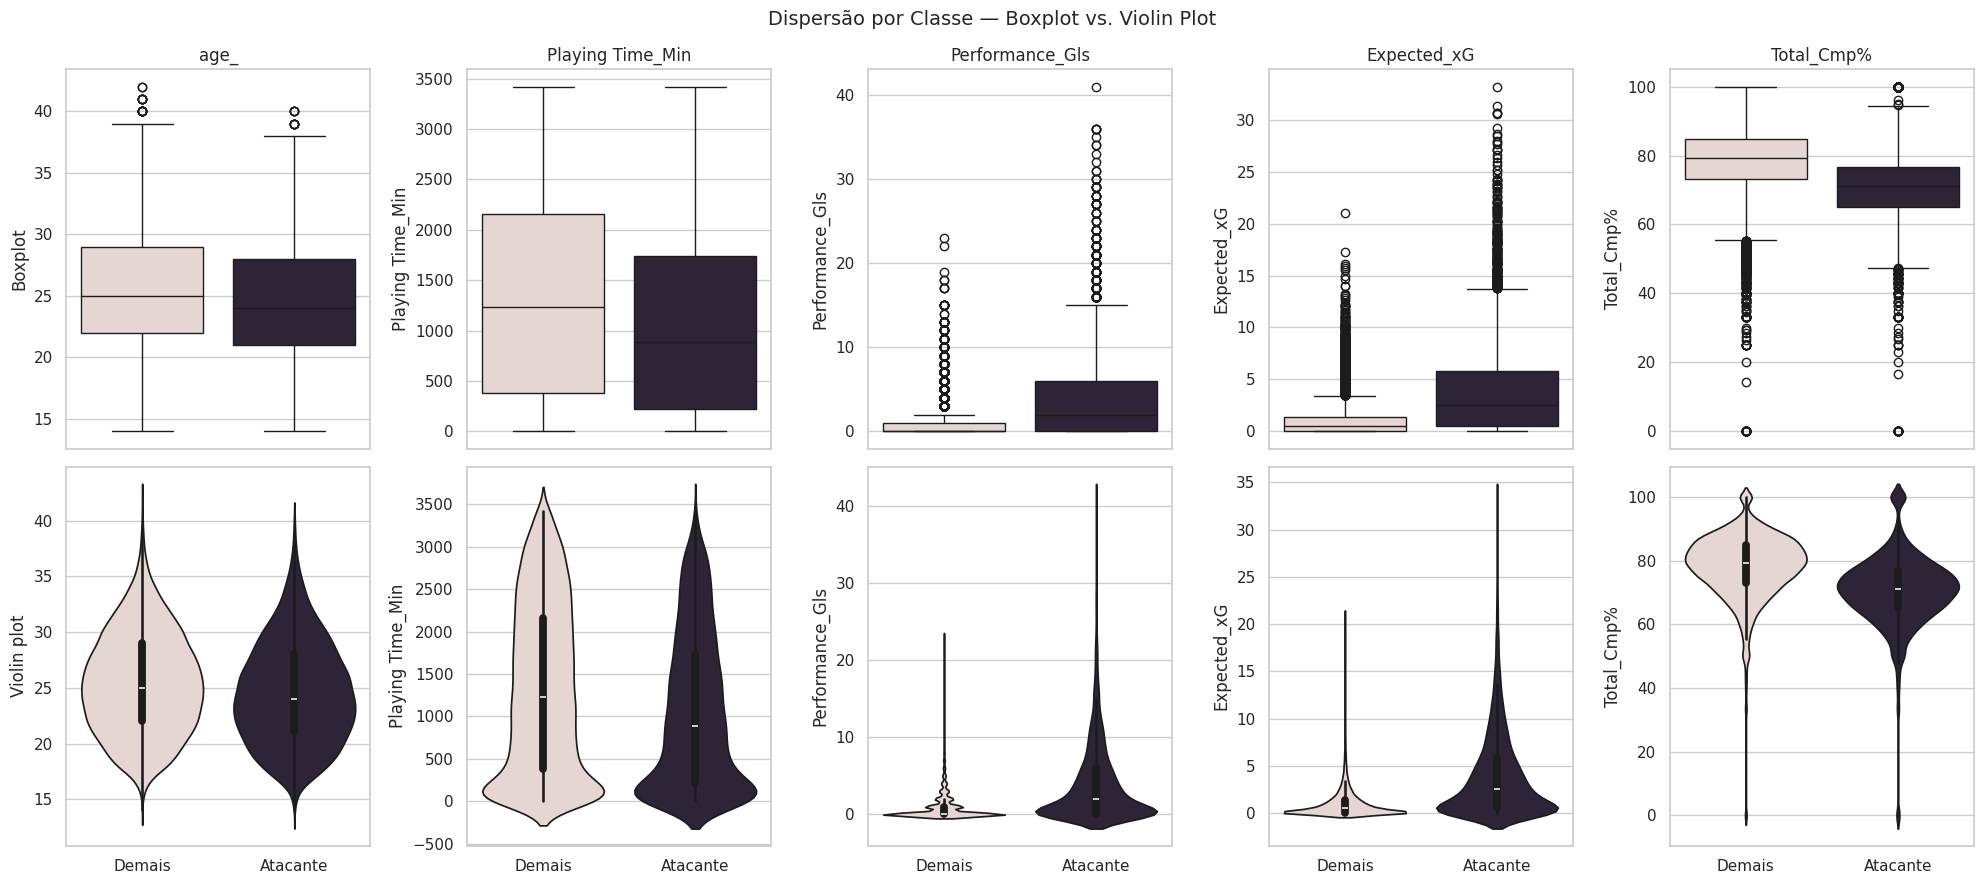

In [ ]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
display(dispersao.round(2))

"""### Boxplot e violin plot por classe"""

palette_classe = {"Demais": COR_CONTEXTO, "Atacante": COR_DESTAQUE}

fig, axes = plt.subplots(2, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 9), sharex="col")

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, x="perfil", y=col, hue="perfil",
                palette=palette_classe, legend=False, ax=axes[0, i])
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")

    sns.violinplot(data=df, x="perfil", y=col, hue="perfil",
                   palette=palette_classe, legend=False, ax=axes[1, i])
    axes[1, i].set_xlabel("")

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin plot")
fig.suptitle("Dispersão por Classe — Boxplot vs. Violin Plot", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável mostra uma caixa (IQR) nitidamente mais alta ou mais baixa entre "Demais" e "Atacante"? Isso já é um indício — antes mesmo da análise bivariada formal — de que essa variável pode ajudar a diferenciar as duas classes.

**Resposta:** Sim. Em `Performance_Gls` e `Expected_xG` a caixa dos atacantes fica nitidamente mais alta: a mediana deles se aproxima (ou passa) do terceiro quartil dos demais jogadores. Em idade e `Playing Time_Min` as caixas praticamente se sobrepõem, e em `Total_Cmp%` os atacantes aparecem até um pouco abaixo, o que faz sentido porque eles arriscam mais passes em zonas de pressão. Ou seja, as métricas ofensivas são as candidatas naturais pra separar os perfis na análise bivariada.

## 4. Tratamento de Dados Ausentes e Outliers

Agora que já vimos o retrato estatístico "antes" (Seção 3), temos a informação que faltava pra decidir como tratar tanto os dados ausentes (as 258 linhas em que todo o bloco `Expected_*` some junto, e os percentuais que ficam vazios quando não houve tentativa) quanto os outliers das variáveis quantitativas. Depois do tratamento, vamos rodar a estatística descritiva mais uma vez ("depois") pra confirmar o efeito das escolhas e fechar o ciclo iterativo que começamos lá na abertura.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [ ]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
        "percentual": round(n_outliers / len(df) * 100, 2),
    }

display(pd.DataFrame(resumo_outliers).T)

"""### Outliers de domínio: alguma linha viola uma regra do futebol?"""

cols_pct = [c for c in df.columns if c.endswith("%")]

regras = {}
if {"Standard_SoT", "Standard_Sh"} <= set(df.columns):
    regras["finalizações no alvo > finalizações"] = int((df["Standard_SoT"] > df["Standard_Sh"]).sum())
    regras["gols > finalizações"] = int((df["Performance_Gls"] > df["Standard_Sh"]).sum())

regras["idade fora de 15 a 45 anos"] = int(((~df[COL_IDADE].between(15, 45)) & df[COL_IDADE].notna()).sum())
regras["percentuais fora de 0 a 100"] = int(((df[cols_pct] < 0) | (df[cols_pct] > 100)).sum().sum())
regras["minutos acima de 38 jogos x 90 min"] = int((df["Playing Time_Min"] > 38 * 90).sum())

display(pd.Series(regras, name="linhas suspeitas").to_frame())

,limite_inferior,limite_superior,n_outliers,percentual
age_,13.00,37.00,91.0,0.41
Playing Time_Min,-2240.50,4643.50,0.0,0.00
Performance_Gls,-3.00,5.00,2054.0,9.16
Expected_xG,-2.90,5.10,2083.0,9.29
Total_Cmp%,50.75,103.15,554.0,2.47


,linhas suspeitas
finalizações no alvo > finalizações,0
gols > finalizações,4
idade fora de 15 a 45 anos,2
percentuais fora de 0 a 100,0
minutos acima de 38 jogos x 90 min,0


### Visualizando os Outliers

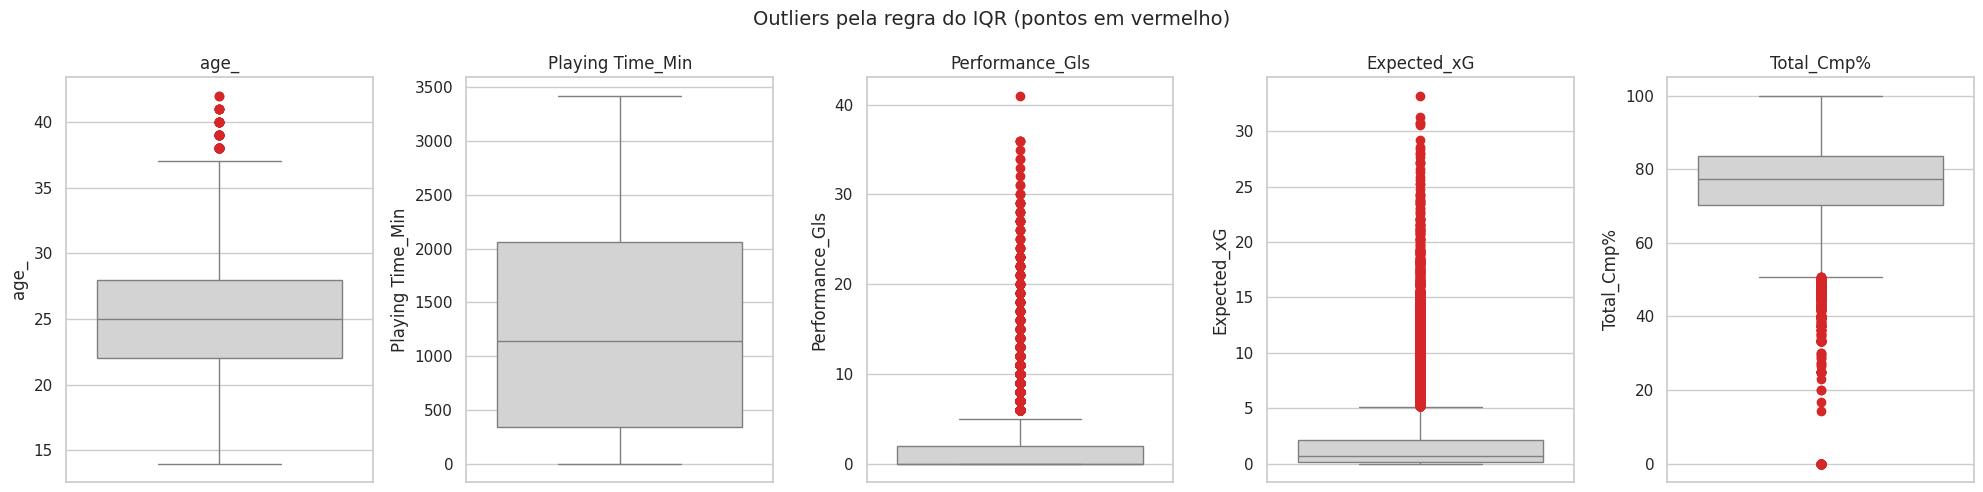

In [ ]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** o slide 26 da aula 9 classifica outliers em três tipos, cada um com um tratamento recomendado:

| Tipo | Cenário | O que fazer? |
|---|---|---|
| Estatístico | Legítimo | Manter / Transformar |
| De domínio | Viola regra de negócio ou condições físicas | Investigar! |
| Erros de dados | Falhas | Corrigir se possível / Remover como última opção |

Olhando os outliers encontrados (principalmente em `Performance_Gls`, `Expected_xG` e `Playing Time_Min`): eles parecem plausíveis dentro do futebol (um artilheiro realmente pode marcar 30 gols em uma temporada), ou parecem violar algum limite físico/regra da competição? Isso muda qual das três categorias se aplica — e, consequentemente, se devemos manter, transformar ou remover.

**Resposta:** os outliers de `Performance_Gls`, `Expected_xG` e `Playing Time_Min` são do tipo **estatístico**: valores raros, mas legítimos. Um artilheiro realmente marca 30 ou 40 gols numa temporada e um titular absoluto realmente joga perto de 3.400 minutos. Eles aparecem como outliers pela regra do IQR justamente porque a maioria da base é de jogadores com pouca participação, o que comprime o IQR. Tratamento: **manter** (e transformar apenas se alguma técnica mais à frente exigir simetria), porque justamente esses jogadores são os mais relevantes em qualquer análise ofensiva.

Para separar isso de um outlier **de domínio** ou de um **erro de dados**, a checagem de regras de negócio no fim da célula de detecção (logo acima) testou combinações impossíveis. Resultado: 0 linhas com finalização no alvo maior que o total de finalizações, 0 percentuais fora de 0–100, 0 jogadores com mais minutos do que 38 jogos permitem, **4 linhas com mais gols do que finalizações** e **2 linhas com idade abaixo de 15 anos**. Investigando as duas suspeitas:

- As 4 linhas de "gols > finalizações" são Jorginho (7 gols, 7 deles de pênalti), Mark Noble, Bonucci e Kevin Vogt (1 gol, 1 pênalti cada). O FBref **não conta cobrança de pênalti em `Standard_Sh`**, mas conta o gol em `Performance_Gls` — ou seja, é definição da métrica, não erro de coleta.
- As idades de 14 anos são Luka Romero e Wisdom Amey, dois estreantes precoces reais do futebol europeu.

Conclusão: nenhum candidato a **erro de dados** se confirmou. Nada precisa ser corrigido ou removido — só documentado, para que ninguém calcule "gols por finalização" sem lembrar que pênaltis ficam de fora do denominador.

### Decidindo o Tratamento dos Dados Ausentes

As ausências possuem mecanismos diferentes e, por isso, recebem tratamentos diferentes:

1. **Percentuais e razões sem tentativa:** serão mantidos como `NaN`. Quando não houve tentativa, a taxa é indefinida; preencher com zero poderia alterar artificialmente a distribuição. As funções usadas na EDA ignoram esses valores quando necessário.
2. **Ausência sistemática nas métricas `Expected_*`:** após a correção das duplicidades, restaram poucas linhas sem esse bloco. Como o volume é muito pequeno e essas métricas são importantes para a análise, essas linhas serão removidas.
3. **Informações essenciais ausentes:** linhas sem posição ou idade também serão removidas, pois essas variáveis são usadas nas comparações.
4. **Médias sem zero natural:** variáveis como `Standard_Dist`, `Subs_Mn/Sub` e `Starts_Mn/Start` continuam como `NaN`, pois preencher com zero criaria uma informação que não existe.

Assim, o tratamento evita inventar valores e mantém as ausências que possuem significado estrutural.

In [ ]:
linhas_antes = df.shape[0]
df_antes = df.copy()

# Percentuais sem denominador continuam como NaN: a taxa é indefinida.
# Removemos somente linhas sem métricas esperadas, posição ou idade.
df = df.dropna(subset=["Expected_xG", COL_POS, COL_IDADE]).reset_index(drop=True)

linhas_depois = df.shape[0]
print(f"Linhas antes: {linhas_antes} | Linhas depois: {linhas_depois} | Removidas: {linhas_antes - linhas_depois}")
print(f"Percentual removido: {(linhas_antes - linhas_depois) / linhas_antes * 100:.2f}%")

ausentes_analise = df[VARS_QUANT].isna().sum()
print("Ausências nas variáveis da análise:")
display(ausentes_analise[ausentes_analise > 0].to_frame("quantidade"))

restantes = df.isna().sum()
restantes = restantes[restantes > 0].sort_values(ascending=False)
print("Colunas que ainda têm ausentes:", len(restantes))
display(restantes.head(5).to_frame("quantidade"))

Linhas antes: 22418 | Linhas depois: 22414 | Removidas: 4
Percentual removido: 0.02%
Ausências nas variáveis da análise:


,quantidade
Total_Cmp%,140


Colunas que ainda têm ausentes: 28


,quantidade
Standard_G/SoT,6890
Subs_Mn/Sub,4963
Starts_Mn/Start,4088
Standard_Dist,4086
Expected_npxG/Sh,4086


### Decidindo o Tratamento dos Outliers

Diferente dos ausentes, aqui **não vamos remover automaticamente**. Pelos valores encontrados (gols, xG e minutos altos, mas dentro do que um jogador de elite realmente produz em uma temporada), a classificação mais provável é **"Estatístico"**: outliers legítimos, não erros de coleta. Sendo assim, o tratamento recomendado é **manter** — a informação é real e é justamente a mais interessante da base, já que são os jogadores decisivos — ou **transformar**, se mais à frente alguma técnica sofrer com a assimetria.

Vamos manter os valores originais por enquanto, mas ilustrar como ficaria uma transformação logarítmica em `Performance_Gls`, útil caso a assimetria atrapalhe algum teste ou modelo em análises futuras.

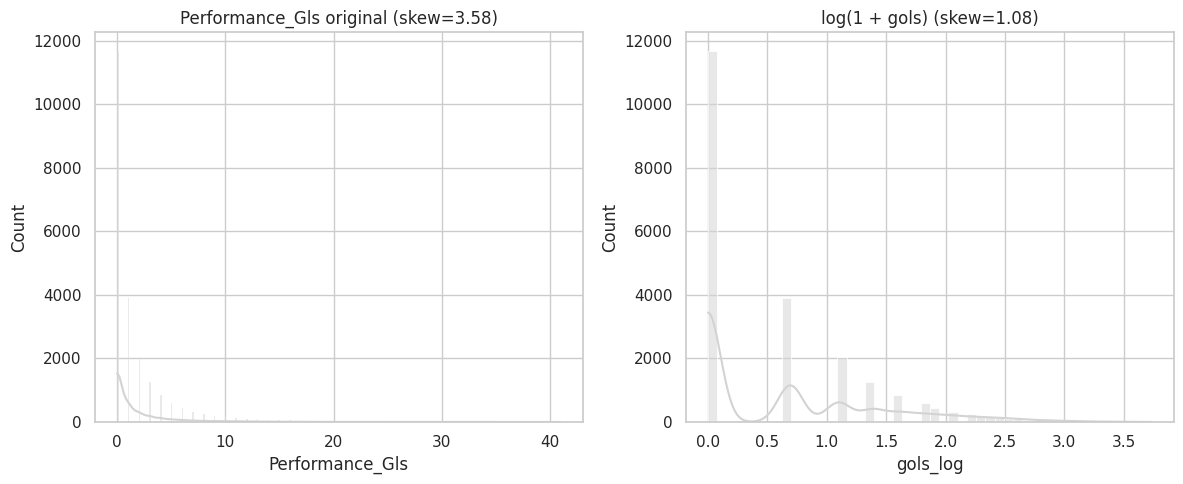

In [ ]:
df["gols_log"] = np.log1p(df["Performance_Gls"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="Performance_Gls", kde=True, color=COR_NEUTRA, ax=axes[0])
axes[0].set_title(f"Performance_Gls original (skew={df['Performance_Gls'].skew():.2f})")

sns.histplot(data=df, x="gols_log", kde=True, color=COR_NEUTRA, ax=axes[1])
axes[1].set_title(f"log(1 + gols) (skew={df['gols_log'].skew():.2f})")

plt.tight_layout()
plt.show()

**Resposta:** sim, e bastante: a assimetria de `Performance_Gls` cai de 3,58 para aproximadamente 1,09 depois do `log1p`. A cauda longa dos artilheiros é comprimida e a distribuição fica mais próxima de algo simétrico, embora o excesso de zeros continue. Isso é uma característica real do futebol, não um defeito do dado. Mantivemos `gols_log` apenas como demonstração e seguimos usando `Performance_Gls` original nas próximas seções, pois a cauda contém informação legítima.

## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: tratamos os ausentes e decidimos manter os outliers. Agora rodamos a mesma bateria de estatísticas da Seção 3 para comparar diretamente com o "antes".

In [ ]:
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
age_,25.21,25.00,4.54,14.00,42.00,0.29,-0.44
Playing Time_Min,1265.32,1139.00,980.32,1.00,3420.00,0.37,-1.07
Performance_Gls,1.73,0.00,3.28,0.00,41.00,3.58,18.34
Expected_xG,1.77,0.70,2.95,0.00,33.20,3.40,16.17
Total_Cmp%,76.24,77.40,11.28,0.00,100.00,-1.48,6.94


### Comparando “antes” e “depois”

In [ ]:
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)
comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
age_,0.285,0.285,-0.435,-0.435,-0.0,0.000
Playing Time_Min,0.371,0.370,-1.068,-1.068,-0.0,-0.000
Performance_Gls,3.582,3.582,18.343,18.340,-0.0,-0.003
Expected_xG,3.405,3.405,16.170,16.169,-0.0,-0.002
Total_Cmp%,-1.475,-1.475,6.936,6.937,-0.0,0.001


**Resposta:** Depois da correção das duplicidades, o tratamento dos dados ausentes removeu apenas 4 linhas (0,02%). As estatísticas mudaram muito pouco. Os percentuais sem tentativa foram mantidos como `NaN`, evitando criar zeros artificiais; por isso, `Total_Cmp%` preservou sua distribuição original.

**Os gols ainda rejeitam normalidade?**

Vamos repetir o teste de Shapiro-Wilk para `Performance_Gls`, agora com os dados tratados.

In [ ]:
VAR_NORMALIDADE = "Performance_Gls"

amostra_antes = df_antes[VAR_NORMALIDADE].dropna().sample(5000, random_state=42)
amostra_depois = df[VAR_NORMALIDADE].dropna().sample(5000, random_state=42)

stat_antes, p_antes = stats.shapiro(amostra_antes)
stat_depois, p_depois = stats.shapiro(amostra_depois)

print(f"Shapiro-Wilk (antes)  — {VAR_NORMALIDADE}: W={stat_antes:.4f}, p-valor={p_antes:.4g}")
print(f"Shapiro-Wilk (depois) — {VAR_NORMALIDADE}: W={stat_depois:.4f}, p-valor={p_depois:.4g}")
print("Rejeita normalidade depois?", "Sim" if p_depois < 0.05 else "Não")

Shapiro-Wilk (antes)  — Performance_Gls: W=0.6006, p-valor=2.299e-75
Shapiro-Wilk (depois) — Performance_Gls: W=0.5809, p-valor=2.215e-76
Rejeita normalidade depois? Sim


**Visualizando antes x depois, lado a lado**

Vamos sobrepor as distribuições de duas variáveis importantes no futebol: `Performance_Gls` e `Expected_xG`, comparando a versão original (`df_antes`) com a tratada (`df`).

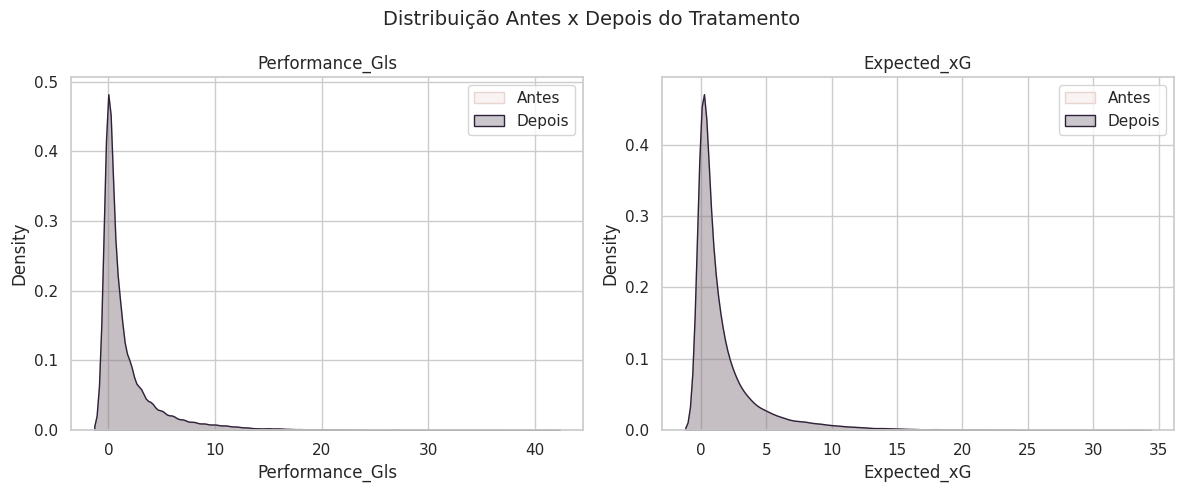

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col in zip(axes, ["Performance_Gls", "Expected_xG"]):
    sns.kdeplot(df_antes[col].dropna(), color=COR_CONTEXTO, fill=True, label="Antes", ax=ax)
    sns.kdeplot(df[col].dropna(), color=COR_DESTAQUE, fill=True, label="Depois", ax=ax)
    ax.set_title(col)
    ax.legend()

fig.suptitle("Distribuição Antes x Depois do Tratamento", fontsize=14)
plt.tight_layout()
plt.show()

**Resposta:** As curvas de antes e depois praticamente se sobrepõem. Isso era esperado, porque poucas linhas foram removidas e os valores extremos plausíveis foram mantidos. Portanto, o tratamento não alterou de forma artificial o comportamento geral dos gols e do xG.

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas.




#### Frequências absolutas e relativas

In [ ]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))

\n--- league ---
                    absoluta  relativa
league                                
ITA-Serie A             4824     0.215
ESP-La Liga             4692     0.209
FRA-Ligue 1             4542     0.203
ENG-Premier League      4358     0.194
GER-Bundesliga          3998     0.178
\n--- season ---
        absoluta  relativa
season                    
2122        2922     0.130
2223        2889     0.129
2425        2852     0.127
2324        2852     0.127
2021        2822     0.126
1920        2732     0.122
1718        2689     0.120
1819        2656     0.118
\n--- pos_principal ---
               absoluta  relativa
pos_principal                    
DF                 7904     0.353
MF                 7276     0.325
FW                 5576     0.249
GK                 1658     0.074
\n--- perfil ---
          absoluta  relativa
perfil                      
Demais       16838     0.751
Atacante      5576     0.249


#### Visualizando as frequências

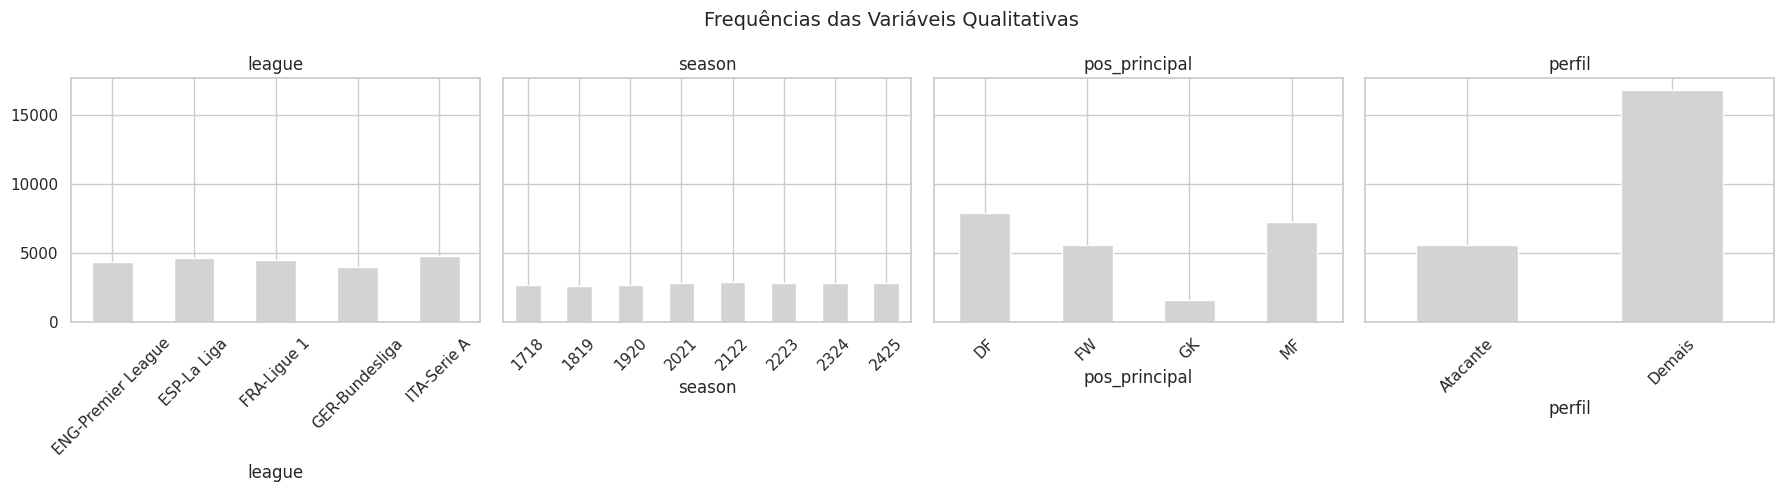

In [ ]:
fig, axes = plt.subplots(1, len(VARS_QUALI), figsize=(18, 5), sharey=True)

for i, col in enumerate(VARS_QUALI):
    df[col].value_counts().sort_index().plot(kind="bar", color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)
    axes[i].tick_params(axis="x", rotation=45)

fig.suptitle("Frequências das Variáveis Qualitativas", fontsize=14)
plt.tight_layout()
plt.show()

**Resposta:** Liga e temporada estão relativamente equilibradas. A posição principal apresenta alguma diferença porque goleiros são menos numerosos. A variável `perfil` também é desbalanceada: 75,1% são “Demais” e 24,9% são “Atacante”. Isso deve ser considerado ao comparar os grupos.

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento** — quantidade da classe majoritária dividida pela minoritária. Quanto maior, mais desbalanceada.
- **Entropia de Shannon normalizada** — 1 indica melhor equilíbrio; valores próximos de 0 indicam forte desbalanceamento.

Vamos aplicar as duas medidas às variáveis qualitativas escolhidas para esta análise.

In [ ]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

pd.DataFrame({
    col: metrica_desbalanceamento(df[col])
    for col in VARS_QUALI
}).T

,n_classes,razao_desbalanceamento,entropia_normalizada
league,5.0,1.21,0.999
season,8.0,1.10,1.000
pos_principal,4.0,4.77,0.917
perfil,2.0,3.02,0.809


**Resposta:** Nenhuma variável apresentou entropia próxima de 0. Liga e temporada estão bem distribuídas entre as categorias. O maior desbalanceamento está em `perfil` (entropia 0,809 e razão 3,02), pois há mais jogadores de outras posições do que atacantes. Mesmo assim, ainda existem observações suficientes nos dois grupos.

### Análise Bivariada

Agora vamos avaliar como as variáveis se relacionam entre si e como o perfil de atacante aparece nessas relações.

#### Quantitativa x Quantitativa — Correlação

Será utilizada apenas a **correlação de Spearman**. Essa escolha faz mais sentido porque as variáveis de gols e xG não seguem distribuição normal, possuem assimetria e valores extremos plausíveis. Spearman trabalha com postos, identifica relações monotônicas e é menos sensível a esses extremos.

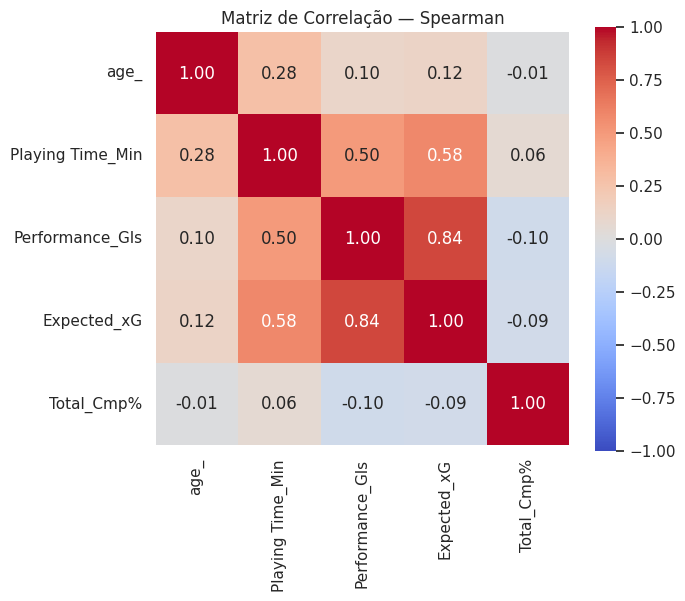

,age_,Playing Time_Min,Performance_Gls,Expected_xG,Total_Cmp%
age_,1.00,0.28,0.10,0.12,-0.01
Playing Time_Min,0.28,1.00,0.50,0.58,0.06
Performance_Gls,0.10,0.50,1.00,0.84,-0.10
Expected_xG,0.12,0.58,0.84,1.00,-0.09
Total_Cmp%,-0.01,0.06,-0.10,-0.09,1.00


In [ ]:
corr_spearman = df[VARS_QUANT].corr(method="spearman")

plt.figure(figsize=(7, 6))
sns.heatmap(
    corr_spearman, annot=True, fmt=".2f", cmap="coolwarm",
    vmin=-1, vmax=1, square=True
)
plt.title("Matriz de Correlação — Spearman")
plt.tight_layout()
plt.show()
corr_spearman.round(2)

Como a matriz é simétrica, o triângulo inferior apresenta as mesmas correlações de Spearman sem repetir os valores.

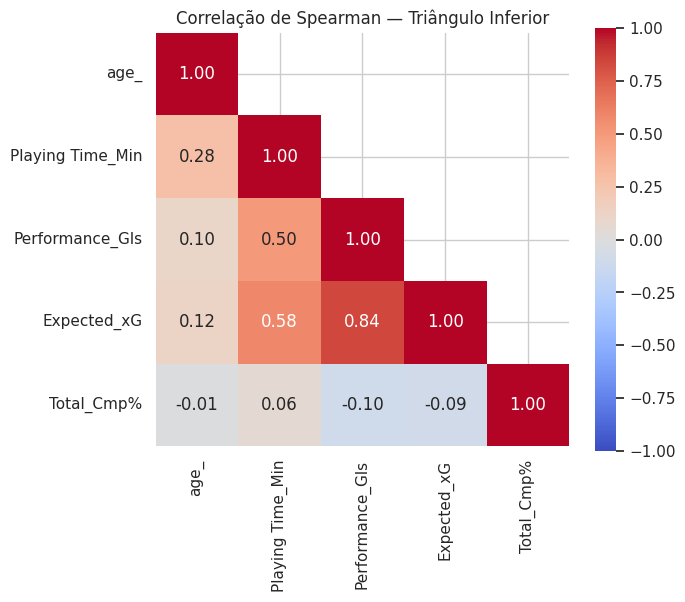

In [ ]:
mask = np.triu(np.ones_like(corr_spearman, dtype=bool), k=1)

plt.figure(figsize=(7, 6))
sns.heatmap(
    corr_spearman, mask=mask, annot=True, fmt=".2f",
    cmap="coolwarm", vmin=-1, vmax=1, square=True
)
plt.title("Correlação de Spearman — Triângulo Inferior")
plt.tight_layout()
plt.show()

**Resposta:** A relação que mais chama atenção é entre `Performance_Gls` e `Expected_xG`, com correlação de Spearman igual a **0,84**, considerada forte. Isso faz sentido: jogadores que acumulam chances de maior qualidade tendem a marcar mais gols. Também aparecem relações moderadas entre minutos e xG (0,58) e entre minutos e gols (0,50).

#### Dispersão entre duas variáveis quantitativas

Escolhemos `Expected_xG` e `Performance_Gls` porque existe uma relação direta de domínio: o xG representa a quantidade e a qualidade das chances, enquanto os gols são o resultado observado. Além disso, esse foi o par com a maior correlação de Spearman (0,84).

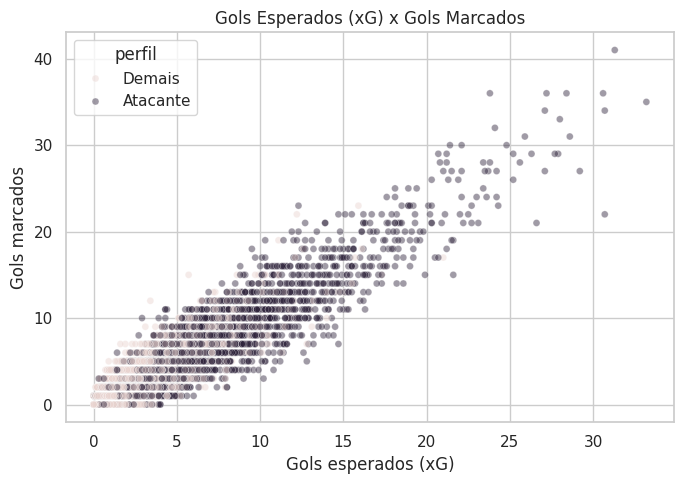

In [ ]:
plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=df, x="Expected_xG", y="Performance_Gls", hue="perfil",
    palette={"Demais": COR_CONTEXTO, "Atacante": COR_DESTAQUE},
    alpha=0.45, s=25
)
plt.title("Gols Esperados (xG) x Gols Marcados")
plt.xlabel("Gols esperados (xG)")
plt.ylabel("Gols marcados")
plt.tight_layout()
plt.show()

**Resposta:** Existe uma tendência crescente clara: conforme o xG aumenta, o número de gols também tende a aumentar. Os atacantes aparecem com maior frequência na região superior direita, mas os grupos se misturam principalmente nos valores baixos. Isso é esperado, porque muitos jogadores de outras posições também finalizam e marcam alguns gols.

#### Opcional

Não realizado.

In [ ]:
# Opcional — não realizado.

**Opcional — não realizado.**

In [ ]:
# Opcional — não realizado.

**Opcional — não realizado.**

#### Opcional

Não realizado.

In [ ]:
# Opcional — não realizado.

**Opcional — não realizado.**

#### Opcional

Não realizado.

In [ ]:
# Opcional — não realizado.

In [ ]:
# Opcional — não realizado.

**Opcional — não realizado.**

In [ ]:
# Opcional — não realizado.

**Opcional — não realizado.**

#### Outliers bivariados

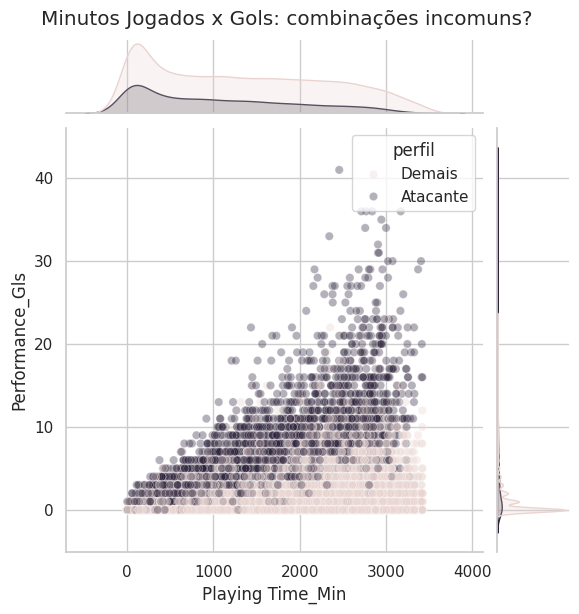

In [ ]:
sns.jointplot(
    data=df, x="Playing Time_Min", y="Performance_Gls", hue="perfil",
    palette={"Demais": COR_CONTEXTO, "Atacante": COR_DESTAQUE},
    alpha=0.35, height=6
)
plt.suptitle("Minutos Jogados x Gols: combinações incomuns?", y=1.02)
plt.show()

**Resposta:** Alguns pontos se destacam pela combinação de muitos minutos e muitos gols. Também existem jogadores com muitos gols em menos minutos. São casos raros, mas plausíveis, como grandes artilheiros ou reservas muito eficientes. Por isso, não devem ser tratados automaticamente como erros.

#### Análise Multivariada

##### Matriz de Correlação

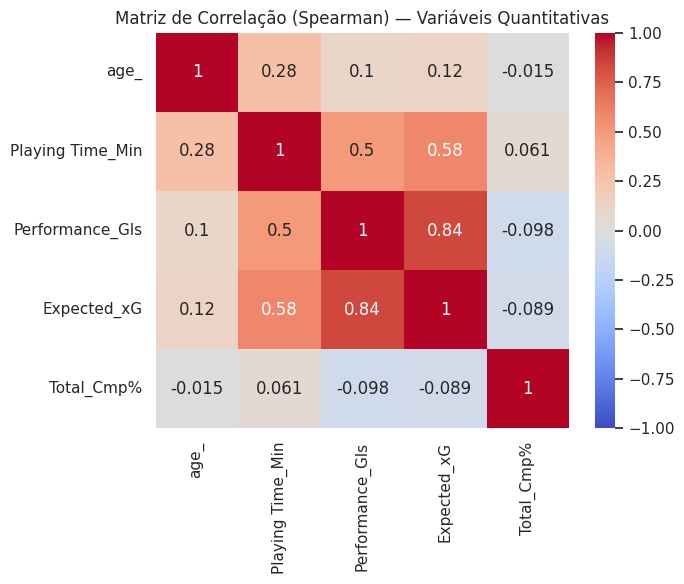

In [ ]:
plt.figure(figsize=(7, 6))
sns.heatmap(df[VARS_QUANT].corr(method="spearman"), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas")
plt.tight_layout()
plt.show()


**Resposta:** A correlação mais forte é entre gols e xG (0,84). Ela pode indicar informação parcialmente redundante, mas as duas variáveis não são iguais: xG mede a qualidade e o volume das chances, enquanto gols mede o resultado. Por isso, ambas continuam úteis na EDA. As demais correlações são moderadas ou fracas.

##### Correlograma

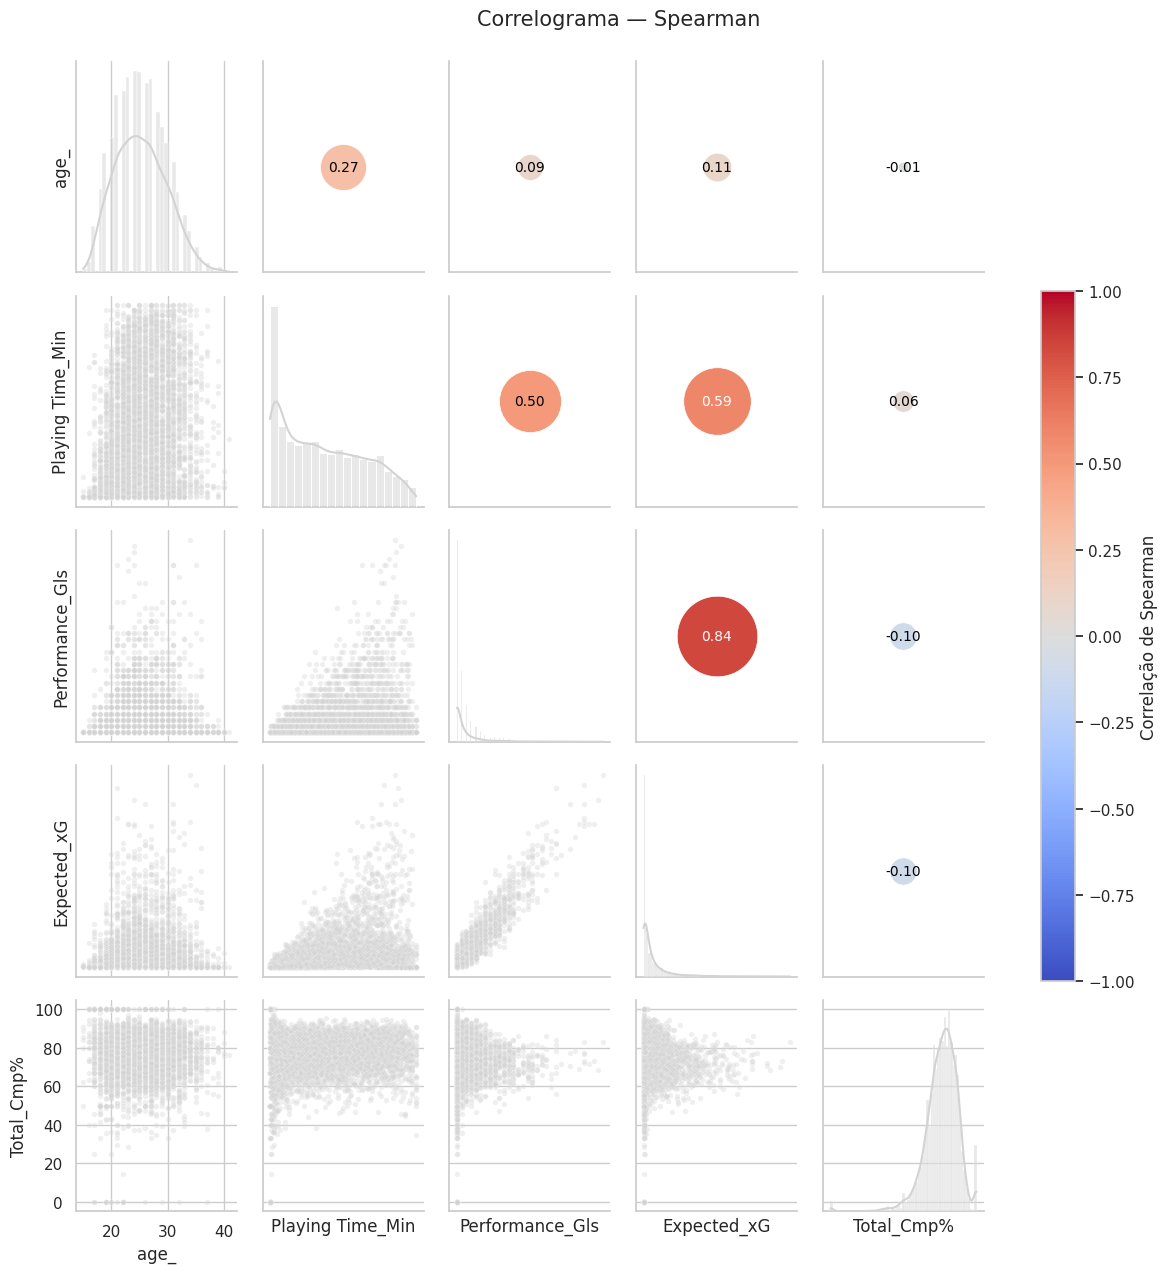

In [ ]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao(x, y, **kwargs):
    r = stats.spearmanr(x, y, nan_policy="omit").statistic
    ax = plt.gca()
    ax.scatter([.5], [.5], s=abs(r) * 4000, c=[r], cmap="coolwarm",
               vmin=-1, vmax=1, transform=ax.transAxes,
               edgecolor="white", linewidth=.5)
    ax.annotate(f"{r:.2f}", xy=(.5, .5), xycoords=ax.transAxes,
                ha="center", va="center", fontsize=10,
                color="white" if abs(r) > .5 else "black")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)

df_amostra = df[VARS_QUANT].sample(5000, random_state=42)
g = sns.PairGrid(df_amostra, diag_sharey=False)
g.map_lower(sns.scatterplot, color=COR_NEUTRA, alpha=.35, s=15)
g.map_diag(sns.histplot, color=COR_NEUTRA, kde=True)
g.map_upper(circulo_correlacao)

sm = ScalarMappable(norm=Normalize(-1, 1), cmap="coolwarm")
sm.set_array([])
g.fig.colorbar(sm, ax=g.axes, shrink=.6, label="Correlação de Spearman")
g.fig.suptitle("Correlograma — Spearman", y=1.02, fontsize=15)
plt.show()

## Síntese final

### Principais conclusões

1. Foram removidos 511 registros redundantes referentes à mesma chave de jogador, liga, temporada e clube. Depois disso, apenas 4 linhas (0,02%) foram removidas por falta de informações essenciais, resultando em 22.414 registros.
2. Gols e xG são bastante assimétricos e continuam não normais. Os valores altos representam jogadores de destaque e foram mantidos.
3. A correlação de Spearman entre gols e xG foi forte (0,84), indicando que jogadores que acumulam chances de maior qualidade tendem a marcar mais.
4. Minutos jogados têm relação moderada com xG (0,58) e com gols (0,50).
5. Ligas e temporadas estão equilibradas. Já o perfil possui cerca de 75% de jogadores das demais posições e 25% de atacantes.

### Declaração de uso de IA

**Ferramenta utilizada:** ChatGPT.

A IA foi usada para "puxar" dataset de futebol, organizar explicações dos dados/como interpretar eles,escrever pequenos trechos de código, revisar a apresentação final. Todas as sugestões foram conferidas após a execução.

In [ ]:
# Célula final sem execução necessária.
# A síntese e a declaração de uso de IA estão apresentadas acima.